# 05. Interpretability and error analysis of the final model E066

**Project:** Kaggle House Prices. **Stage:** after ensembles (notebook 04).

This notebook only **displays** the tables and figures written by `experiments/interpretability/run_interpretability.py --experiment E066` (folders `outputs/interpretability/` and `outputs/figures/`). It refits nothing, does not write the registry and does not touch the holdout. The written discussion is in `docs/drafts/INTERPRETABILITY_E066.md`.

Residual = actual minus predicted on the log scale, so a negative residual is an over-prediction. Out-of-fold predictions use the seed-42 selection folds.

In [1]:
# Resolve the project root the same way notebook 01 does: walk up until data_description.txt is found.
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "data_description.txt").exists():
    if root == root.parent:
        raise FileNotFoundError("Project root (data_description.txt) not found")
    root = root.parent
os.chdir(root)
print("Working directory:", Path.cwd())

Working directory: C:\Users\Enrique Baena\Desktop\HousePricingKaglle


In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 170)
TAB = Path("outputs/interpretability")
FIG = Path("outputs/figures")
EID = "E066"

def show(name, width=7):
    img = mpimg.imread(FIG / f"{EID}_{name}.png")
    h, w = img.shape[:2]
    plt.figure(figsize=(width, width * h / w))
    plt.imshow(img); plt.axis("off"); plt.show()

## 1. How good is each fold, and how concentrated is the error?

In [3]:
oof = pd.read_csv(TAB / f"{EID}_oof_predictions.csv")
r2 = oof["residual"] ** 2
summary = pd.Series({
    "rows": len(oof),
    "pooled OOF RMSE": np.sqrt(r2.mean()),
    "share of squared error, worst 5 rows": r2.nlargest(5).sum() / r2.sum(),
    "share of squared error, worst 15 rows": r2.nlargest(15).sum() / r2.sum(),
    "share of rows with |residual| > 0.2": (oof["residual"].abs() > 0.2).mean(),
    "RMSE without GrLivArea > 4000 (4 houses)": np.sqrt((oof.loc[oof["GrLivArea"] <= 4000, "residual"] ** 2).mean()),
})
display(summary.round(4).to_frame("value"))

,value
rows,1241.0000
pooled OOF RMSE,0.1190
"share of squared error, worst 5 rows",0.1355
"share of squared error, worst 15 rows",0.3107
share of rows with |residual| > 0.2,0.0661
RMSE without GrLivArea > 4000 (4 houses),0.1140


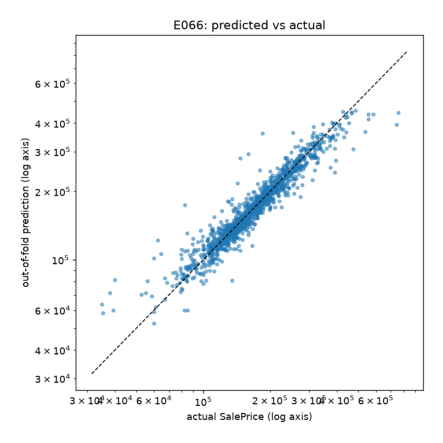

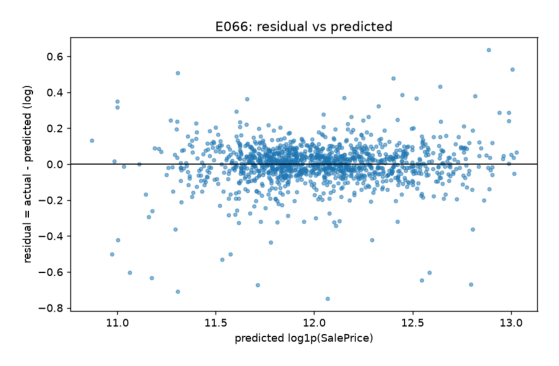

In [4]:
show("pred_vs_actual", 5.5)
show("residual_vs_predicted", 7)

## 2. Where it fails: price deciles, living area, neighbourhoods, worst rows

,price_decile,n,rmse,mean_signed_residual,price_min,price_max
0,D1,126.0,0.2154,-0.0972,34900.0,106500.0
1,D2,125.0,0.1019,-0.0205,107000.0,124000.0
2,D3,122.0,0.0947,-0.0025,124500.0,135500.0
3,D4,128.0,0.1064,-0.0001,135750.0,147000.0
4,D5,122.0,0.0943,0.0140,147400.0,163000.0
5,D6,122.0,0.0760,0.0142,163500.0,179200.0
6,D7,124.0,0.0912,-0.0068,179500.0,198500.0
7,D8,127.0,0.0817,0.0119,198900.0,230000.0
8,D9,121.0,0.1047,0.0146,230500.0,277500.0
9,D10,124.0,0.1528,0.0718,278000.0,755000.0


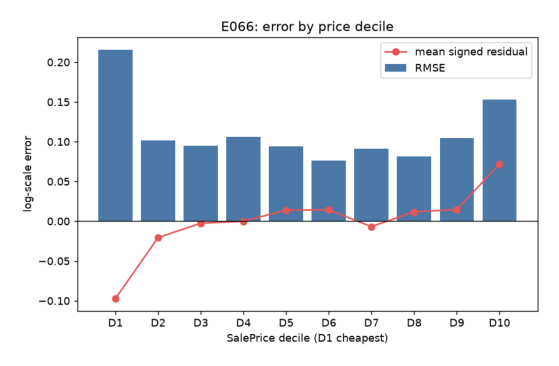

,grliv_bin,n,rmse,mean_signed_residual
0,<1000,197.0,0.1342,-0.0147
1,1000-1499,467.0,0.1144,-0.0019
2,1500-1999,393.0,0.0933,0.0049
3,2000-2499,121.0,0.1249,-0.0033
4,2500-2999,47.0,0.1158,0.0171
5,3000-3999,12.0,0.2006,0.1006
6,>=4000,4.0,0.6114,-0.0269


,Neighborhood,n,rmse,mean_signed_residual,group
0,IDOTRR,29.0,0.2388,-0.0580,worst5
1,Edwards,86.0,0.1653,-0.0215,worst5
2,NoRidge,34.0,0.1616,0.0559,worst5
3,StoneBr,21.0,0.1565,0.0680,worst5
4,OldTown,95.0,0.1560,-0.0220,worst5
5,CollgCr,130.0,0.0693,-0.0049,best5
6,BrDale,14.0,0.0663,-0.0118,best5
7,Gilbert,60.0,0.0626,0.0090,best5
8,NPkVill,7.0,0.0456,0.0159,best5
9,Blueste,2.0,0.0158,-0.0139,best5


,Id,actual,pred,residual,Neighborhood,GrLivArea,OverallQual,YearBuilt,SaleCondition,MSSubClass
0,633,82500.0,174334.779,-0.748,NWAmes,1411,7,1977,Family,20
1,31,40000.0,81358.326,-0.710,IDOTRR,1317,4,1920,Normal,70
2,463,62383.0,122088.514,-0.671,Sawyer,864,5,1965,Normal,20
3,524,184750.0,360786.598,-0.669,Edwards,4676,10,2007,Partial,60
4,1325,147000.0,280911.189,-0.648,Somerst,1795,8,2006,Partial,20
5,1183,745000.0,394416.078,0.636,NoRidge,4476,10,1996,Abnorml,60
6,969,37900.0,71352.345,-0.633,OldTown,968,3,1910,Abnorml,50
7,1299,160000.0,292371.361,-0.603,Edwards,5642,10,2008,Partial,60
8,496,34900.0,63710.386,-0.602,IDOTRR,720,4,1920,Abnorml,30
9,411,60000.0,101919.554,-0.530,Edwards,1276,5,1958,Abnorml,20


In [5]:
display(pd.read_csv(TAB / f"{EID}_residuals_by_price_decile.csv").round(4))
show("residual_by_decile", 7)
display(pd.read_csv(TAB / f"{EID}_residuals_by_grlivarea.csv").round(4))
display(pd.read_csv(TAB / f"{EID}_residuals_by_neighborhood_top_bottom5.csv").round(4))
display(pd.read_csv(TAB / f"{EID}_worst15_rows.csv").round(3))

## 3. What the model uses: permutation importance on validation folds

Each raw column is shuffled in the validation part of each fold; the bar is the rise in RMSE. Correlated columns (GrLivArea, TotalSF and the quality interactions) share credit, so read the ranking as marginal damage, not as a partition of importance.

,column,importance_mean,importance_std_across_folds,n_folds_positive
0,OverallQual_x_TotalSF,0.06373,0.01072,5
1,OverallQual_x_GrLivArea,0.02137,0.00751,5
2,TotalSF,0.01659,0.00441,5
3,OverallCond,0.00785,0.00230,5
4,MSZoning,0.00578,0.00261,5
5,OverallQual,0.00566,0.00285,5
6,LotArea,0.00560,0.00152,5
7,Neighborhood,0.00555,0.00171,5
8,TotalBath,0.00554,0.00137,5
9,GrLivArea,0.00271,0.00115,5


columns: 99 | importance > 0.001: 32 | zero or negative: 16


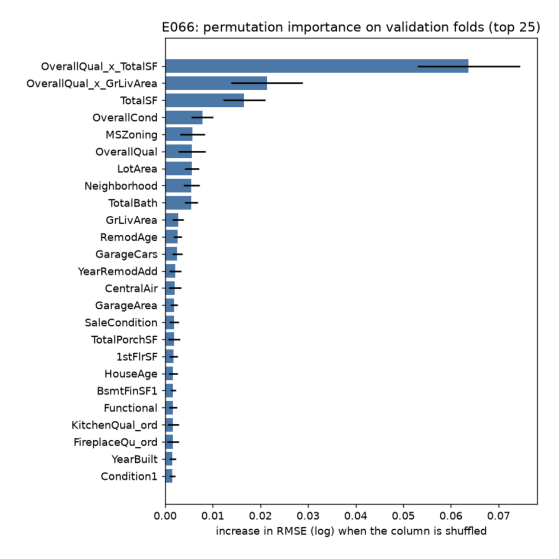

In [6]:
perm = pd.read_csv(TAB / f"{EID}_permutation_importance.csv")
display(perm.head(15).round(5))
print("columns:", len(perm), "| importance > 0.001:", int((perm["importance_mean"] > 0.001).sum()),
      "| zero or negative:", int((perm["importance_mean"] <= 0).sum()))
show("permutation_top25", 7)

## 4. What the model uses: SHAP

SHAP explains the fitted model on the development rows (in-sample): it shows how the model uses its columns, not how well it generalises. One-hot levels are summed back to their raw column in the second table.

,source_column,sum_of_mean_abs_shap
0,OverallQual_x_TotalSF,0.07142
1,OverallQual_x_GrLivArea,0.03241
2,TotalSF,0.02553
3,OverallCond,0.01993
4,Neighborhood,0.01948
5,TotalBath,0.01861
6,LotArea,0.01459
7,OverallQual,0.01455
8,MSZoning,0.01293
9,RemodAge,0.01243


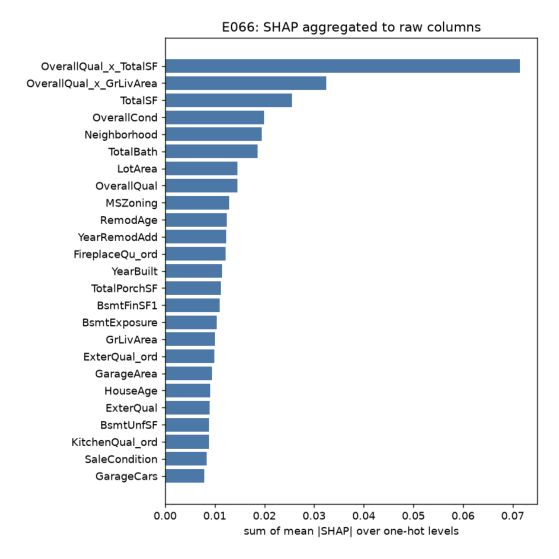

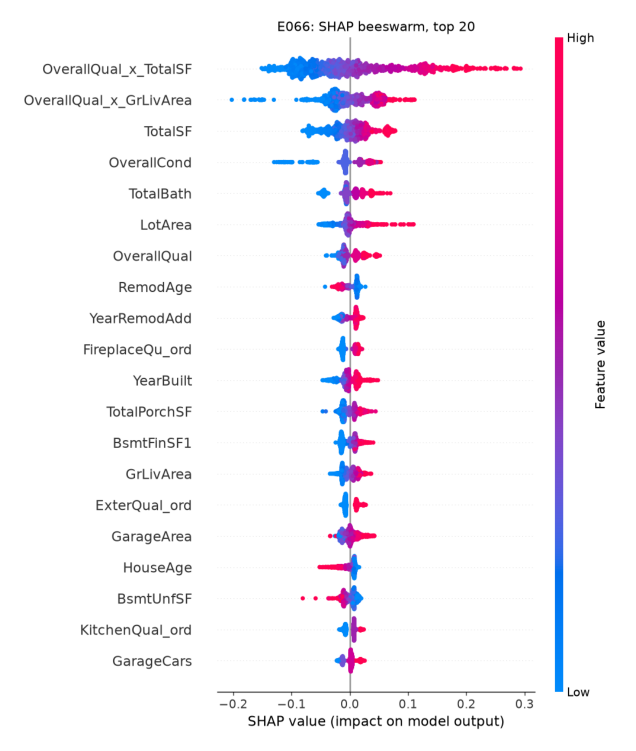

In [7]:
display(pd.read_csv(TAB / f"{EID}_shap_mean_abs_by_raw_column.csv").head(15).round(5))
show("shap_top25_raw_bar", 7)
show("shap_beeswarm", 8)

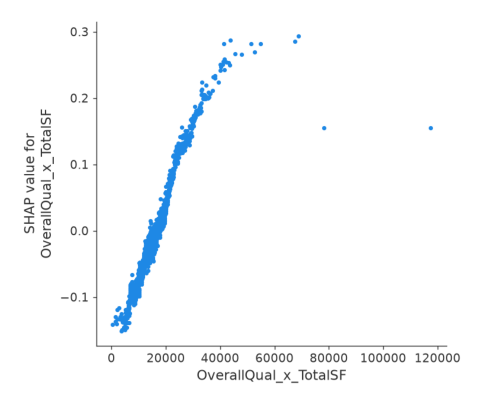

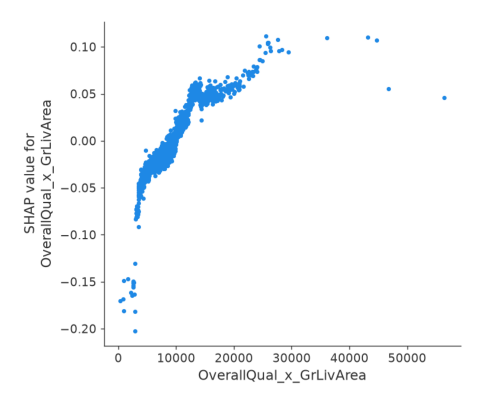

In [8]:
show("shap_dependence_1", 6)
show("shap_dependence_2", 6)